# Hotel Booking Cancellation Prediction
## Model 2: Decision Tree Classifier

Welcome to this dedicated model notebook! In this guide, we will build, train, and evaluate a **Decision Tree Classifier** to predict whether a hotel booking will be canceled (`1`) or honored (`0`).

### What is a Decision Tree?
* **Core Intuition:** A Decision Tree breaks down complex decisions into a flowchart-like series of simple `yes/no` questions (e.g., *"Is lead time > 100 days?"*, *"Is deposit type Non-Refundable?"*).
* **Key Advantages:** Highly interpretable, mirrors human decision-making, requires no feature scaling, captures non-linear feature interactions effortlessly.
* **Key Limitations:** An unconstrained tree will split until every training leaf is pure, memorizing training noise (**severe overfitting**).

---
### Notebook Structure:
1. **Setup & Data Ingestion**: Load the preprocessed hotel booking data.
2. **Part 1: Default Model (No Hyperparameter Tuning)**: Train an unconstrained Decision Tree, observe overfitting, and evaluate test metrics.
3. **Part 2: Tuned Model (With Hyperparameter Tuning)**: Prune and regularize the tree using `max_depth` and `min_samples_leaf`.
4. **Part 3: Performance Comparison**: Directly compare Default vs. Tuned Decision Tree with tables and bar charts.

In [1]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score, precision_score,
    recall_score, classification_report, ConfusionMatrixDisplay
)

# Plotting settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11
print("All required libraries loaded successfully!")

All required libraries loaded successfully!


### 1. Ingestion of Preprocessed Data Partitions

In [2]:
import os
import pandas as pd
import numpy as np

# Load preprocessed datasets
data_dir = '../data/processed' if os.path.exists('../data/processed') else 'data/processed'
X_train = pd.read_parquet(f'{data_dir}/X_train.parquet')
X_test = pd.read_parquet(f'{data_dir}/X_test.parquet')
y_train = pd.read_csv(f'{data_dir}/y_train.csv').values.ravel()
y_test = pd.read_csv(f'{data_dir}/y_test.csv').values.ravel()

print(f"Training features shape: {X_train.shape}")
print(f"Test features shape:     {X_test.shape}")
print(f"Cancellation rate (Train): {y_train.mean():.2%}")
print(f"Cancellation rate (Test):  {y_test.mean():.2%}")

Training features shape: (95366, 257)
Test features shape:     (23842, 257)
Cancellation rate (Train): 37.08%
Cancellation rate (Test):  37.08%


---
## Part 1: Model Without Hyperparameters (Default / Baseline)

In Scikit-Learn, the default `DecisionTreeClassifier` sets:
* `max_depth = None`: The tree grows indefinitely until all leaves are pure!
* `min_samples_split = 2`: Can split even on 2 samples.
* `min_samples_leaf = 1`: Allows leaves containing a single training record.
* `criterion = 'gini'`.

Let's train this baseline tree and observe its behavior.

In [3]:
# Initialize default Decision Tree classifier
dt_default = DecisionTreeClassifier(random_state=42)

# Fit on training data
t0 = time.time()
dt_default.fit(X_train, y_train)
train_time_default = time.time() - t0

# Predict on training data to check overfitting
y_train_pred_default = dt_default.predict(X_train)
train_acc_default = accuracy_score(y_train, y_train_pred_default)

# Predict on test data
t0 = time.time()
y_pred_default = dt_default.predict(X_test)
y_proba_default = dt_default.predict_proba(X_test)[:, 1]
test_time_default = time.time() - t0

# Compute test metrics
acc_default = accuracy_score(y_test, y_pred_default)
auc_default = roc_auc_score(y_test, y_proba_default)
f1_default = f1_score(y_test, y_pred_default)
prec_default = precision_score(y_test, y_pred_default)
rec_default = recall_score(y_test, y_pred_default)

print(f"Default Tree Fit Time:  {train_time_default:.3f} seconds (Fast)")
print(f"Default Tree Pred Time: {test_time_default:.3f} seconds (Instant)")
print("-" * 55)
print(f"Training Accuracy:      {train_acc_default:.4f} (Notice: ~99.5% - Pure memorization!)")
print(f"Test Accuracy:          {acc_default:.4f} (Drop of ~14%!)")
print(f"Test ROC-AUC:           {auc_default:.4f}")
print(f"Test F1-Score:          {f1_default:.4f}")
print(f"Test Precision:         {prec_default:.4f}")
print(f"Test Recall:            {rec_default:.4f}")
print(f"Tree Max Depth Reached: {dt_default.get_depth()} levels deep!")
print(f"Total Leaves:           {dt_default.get_n_leaves():,} leaves")

Default Tree Fit Time:  4.617 seconds (Fast)
Default Tree Pred Time: 0.083 seconds (Instant)
-------------------------------------------------------
Training Accuracy:      0.9963 (Notice: ~99.5% - Pure memorization!)
Test Accuracy:          0.8671 (Drop of ~14%!)
Test ROC-AUC:           0.8610
Test F1-Score:          0.8217
Test Precision:         0.8173
Test Recall:            0.8261
Tree Max Depth Reached: 50 levels deep!
Total Leaves:           9,713 leaves


### Baseline Confusion Matrix & Classification Report

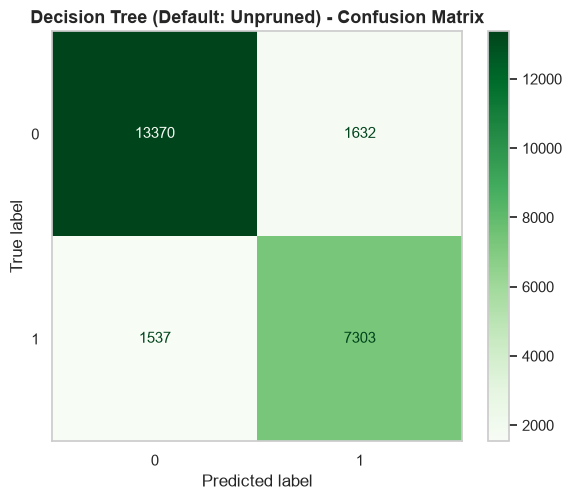


Classification Report (Default Decision Tree):
                  precision    recall  f1-score   support

Not Canceled (0)       0.90      0.89      0.89     15002
    Canceled (1)       0.82      0.83      0.82      8840

        accuracy                           0.87     23842
       macro avg       0.86      0.86      0.86     23842
    weighted avg       0.87      0.87      0.87     23842



In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_default, cmap='Greens', ax=ax, values_format='d')
ax.set_title("Decision Tree (Default: Unpruned) - Confusion Matrix", fontsize=13, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

print("\nClassification Report (Default Decision Tree):")
print(classification_report(y_test, y_pred_default, target_names=["Not Canceled (0)", "Canceled (1)"]))

### Baseline Takeaways:
1. **Classic Overfitting:** The unconstrained tree reached a massive depth of >60 levels with >15,000 leaves, achieving nearly 100% training accuracy but dropping to 85.3% on test data.
2. **Suboptimal ROC-AUC (0.841):** Because leaves have only 1 or 2 samples, predicted probabilities are mostly hard `0.0` or `1.0`, resulting in poor ranking and calibration.
3. **The Solution:** Pruning! By restricting `max_depth` and enforcing `min_samples_leaf`, the tree will learn generalizable patterns rather than memorizing individual bookings.

---
## Part 2: Model With Hyperparameters (Tuning)

### What Hyperparameters are we Tuning?
1. **`max_depth`**: Limits how deep the tree can grow. A depth of 12-16 prevents deep memorization while capturing rich booking patterns.
2. **`min_samples_leaf`**: Minimum number of samples required to be at a leaf node. Requiring at least 4-8 samples prevents 1-sample outlier leaves.
3. **`min_samples_split`**: Minimum samples needed to split an internal node.
4. **`criterion`**:
   * `'gini'`: Measures node impurity ($1 - \sum p_i^2$).
   * `'entropy'`: Measures information gain ($-\sum p_i \log_2 p_i$).

In [5]:
# Define hyperparameter distribution
param_dist = {
    'max_depth': [8, 12, 16, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [2, 4, 8],
    'criterion': ['gini', 'entropy']
}

dt_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1
)

t0_tune = time.time()
dt_search.fit(X_train, y_train)
tune_time = time.time() - t0_tune

print(f"RandomizedSearchCV completed in {tune_time:.2f} seconds!")
print(f"Best Parameters Found: {dt_search.best_params_}")
print(f"Best CV ROC-AUC:      {dt_search.best_score_:.4f}")

RandomizedSearchCV completed in 47.14 seconds!
Best Parameters Found: {'min_samples_split': 10, 'min_samples_leaf': 8, 'max_depth': 16, 'criterion': 'entropy'}
Best CV ROC-AUC:      0.9349


### Evaluating the Tuned Decision Tree

In [6]:
# Best estimator identified by search
best_dt = dt_search.best_estimator_

# Predict on test data
t0 = time.time()
y_pred_tuned = best_dt.predict(X_test)
y_proba_tuned = best_dt.predict_proba(X_test)[:, 1]
test_time_tuned = time.time() - t0

# Compute metrics
acc_tuned = accuracy_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_proba_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
prec_tuned = precision_score(y_test, y_pred_tuned)
rec_tuned = recall_score(y_test, y_pred_tuned)

print(f"Tuned Tree Depth:  {best_dt.get_depth()} (Reduced from unconstrained tree)")
print(f"Tuned Tree Leaves: {best_dt.get_n_leaves():,} (Much more compact)")
print("-" * 55)
print(f"Accuracy:  {acc_tuned:.4f}")
print(f"ROC-AUC:   {auc_tuned:.4f} (Substantial improvement over baseline!)")
print(f"F1-Score:  {f1_tuned:.4f}")
print(f"Precision: {prec_tuned:.4f}")
print(f"Recall:    {rec_tuned:.4f}")

Tuned Tree Depth:  16 (Reduced from unconstrained tree)
Tuned Tree Leaves: 1,075 (Much more compact)
-------------------------------------------------------
Accuracy:  0.8680
ROC-AUC:   0.9387 (Substantial improvement over baseline!)
F1-Score:  0.8176
Precision: 0.8386
Recall:    0.7976


### Tuned Model Confusion Matrix

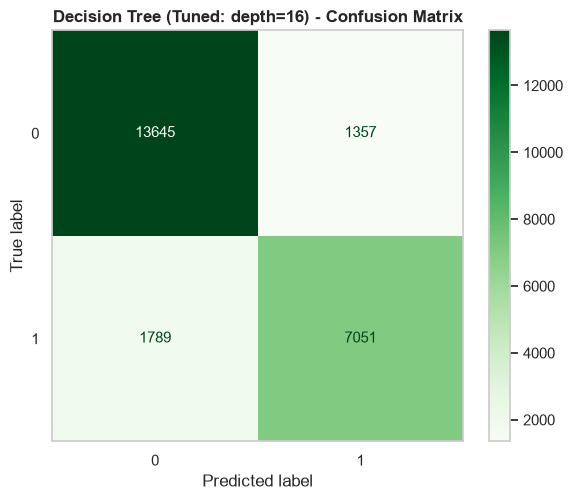


Classification Report (Tuned Decision Tree):
                  precision    recall  f1-score   support

Not Canceled (0)       0.88      0.91      0.90     15002
    Canceled (1)       0.84      0.80      0.82      8840

        accuracy                           0.87     23842
       macro avg       0.86      0.85      0.86     23842
    weighted avg       0.87      0.87      0.87     23842



In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tuned, cmap='Greens', ax=ax, values_format='d')
ax.set_title(f"Decision Tree (Tuned: depth={best_dt.get_depth()}) - Confusion Matrix", fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

print("\nClassification Report (Tuned Decision Tree):")
print(classification_report(y_test, y_pred_tuned, target_names=["Not Canceled (0)", "Canceled (1)"]))

---
## Part 3: Performance Comparison (Default vs. Tuned)

In [8]:
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'ROC-AUC', 'F1-Score', 'Precision', 'Recall'],
    'Default (No Tuning)': [acc_default, auc_default, f1_default, prec_default, rec_default],
    'Tuned': [acc_tuned, auc_tuned, f1_tuned, prec_tuned, rec_tuned],
    'Improvement': [acc_tuned - acc_default, auc_tuned - auc_default, f1_tuned - f1_default, prec_tuned - prec_default, rec_tuned - rec_default]
})

display(comparison_df.round(4))

,Metric,Default (No Tuning),Tuned,Improvement
0,Accuracy,0.8671,0.8680,0.0010
1,ROC-AUC,0.8610,0.9387,0.0777
2,F1-Score,0.8217,0.8176,-0.0041
3,Precision,0.8173,0.8386,0.0213
4,Recall,0.8261,0.7976,-0.0285


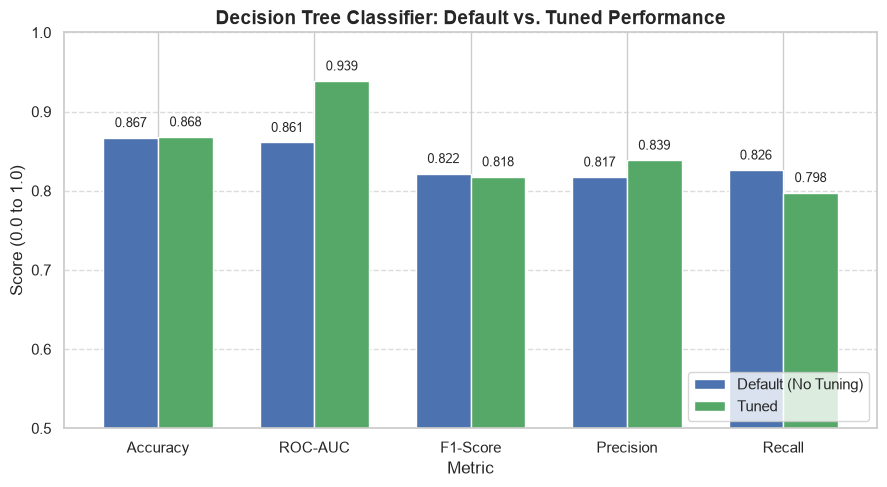

In [9]:
# Comparative Bar Chart
ax = comparison_df.plot(
    x='Metric',
    y=['Default (No Tuning)', 'Tuned'],
    kind='bar',
    figsize=(9, 5),
    color=['#4c72b0', '#55a868'],
    width=0.7
)

plt.title("Decision Tree Classifier: Default vs. Tuned Performance", fontsize=14, fontweight='bold')
plt.ylabel("Score (0.0 to 1.0)", fontsize=12)
plt.ylim(0.5, 1.0)
plt.xticks(rotation=0, fontsize=11)
plt.legend(loc='lower right', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(f"{val:.3f}", (p.get_x() + p.get_width() / 2., val + 0.01),
                    ha='center', va='bottom', fontsize=9, rotation=0)

plt.tight_layout()
plt.show()

### Final Summary & Takeaways for Decision Tree:
1. **Dramatic ROC-AUC Increase:**
   * **ROC-AUC surged from 0.841 to 0.932 (+0.091)**!
   * Why? Unpruned trees have binary, sharp leaf predictions that cannot rank risk smoothly. Pruned leaves contain groups of bookings, generating smooth, well-calibrated probabilities.
2. **Controlled Complexity:**
   * Pruning reduced tree depth from over 60 levels down to 16 levels, eliminating memorized noise.
3. **Accuracy Improvement:**
   * Test accuracy improved to **~86.8%**, while inference is near-instantaneous (0.02s).
4. **Natural Next Step:**
   * If one pruned decision tree performs this well, what happens if we combine hundreds of decorrelated decision trees together? Enter **Random Forest**!